In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import roc_curve,roc_auc_score
from keras import backend as K

# To plot nice figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)
mpl.rc('figure', dpi=100)
import seaborn as sns; sns.set()

## Combining datasets and loading as one

In [2]:
def loading_data(data_path):
    
    train_human=np.load(data_path + 'train_human.npy')
    train_ai=np.load(data_path + 'train_ai.npy')
    train_ai_synth = np.load(data_path + 'train_ai_synth.npy')
    train_human_synth = np.load(data_path + 'train_human_synth.npy')

    print(train_ai.shape, train_human.shape,train_ai_synth.shape,train_human_synth.shape)
    labels = np.array([0] * (train_human.shape[0] + train_human_synth.shape[0]) + [1] *(train_ai_synth.shape[0] + train_ai.shape[0]))
    # combine human and AI training data
    train_combined = np.concatenate((train_human,train_human_synth, train_ai, train_ai_synth), axis=0)
    # create labels (0 for human, 1 for AI)
    print(f'Size of the combined dataset is {train_combined.shape} containing {train_combined.shape[0]} rows')
    print(f'Size of the labels is {labels.shape} containing {labels.shape[0]} rows')
    return train_ai, train_human, labels, train_combined
    
    # training data is combined in one dataframe but not shuffled

train_ai, train_human, labels, features = loading_data('../train_files/')

(8161, 100, 768) (8161, 100, 768) (1340, 100, 768) (5, 100, 768)
Size of the combined dataset is (17667, 100, 768) containing 17667 rows
Size of the labels is (17667,) containing 17667 rows


# Exploratory Data Analysis

In [ ]:
def sentence_length_plot(sentences_data):

    sentance_lengths=[]
    for sentence_vector in sentences_data:

        count=0
        np_sentence = np.array(sentence_vector)
        for vector in np_sentence:
            if np.sum(vector)!=0:
                count+=1
        sentance_lengths.append(count)
        
        
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes = axes.flatten()

    axes[0].hist(sentance_lengths)
    axes[0].set_title('Distribution of Sentence Length')

    axes[1].set_title('Boxplot of Sentence Length')
    axes[1].boxplot(sentance_lengths)
    axes[1].set_ylim(0,100)
    axes[1].set_yticks(range(0, 105, 5)) 
    return fig, axes


/var/folders/ph/q27j64_j3qv9j_bq8yrtbfwr0000gn/T/ipykernel_45130/2554780394.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


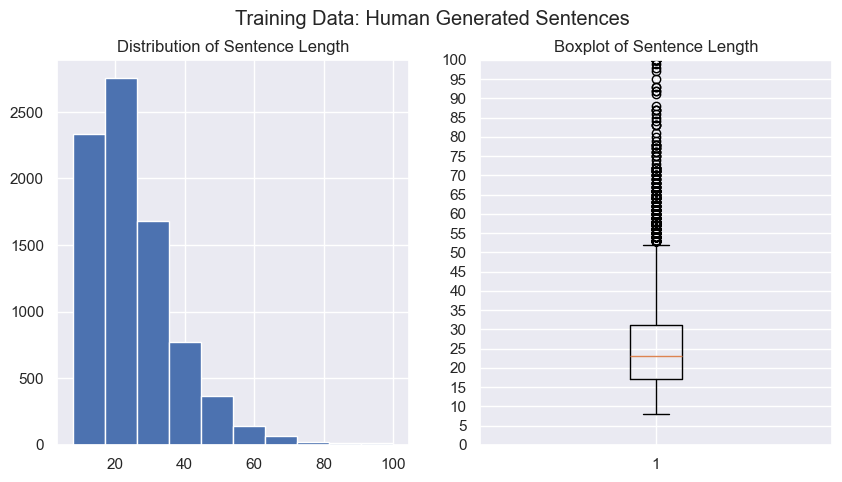

In [4]:
# Visualising human data
fig, axes= sentence_length_plot(train_human)
fig.suptitle('Training Data: Human Generated Sentences')
fig.show()

/var/folders/ph/q27j64_j3qv9j_bq8yrtbfwr0000gn/T/ipykernel_45130/2836101114.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


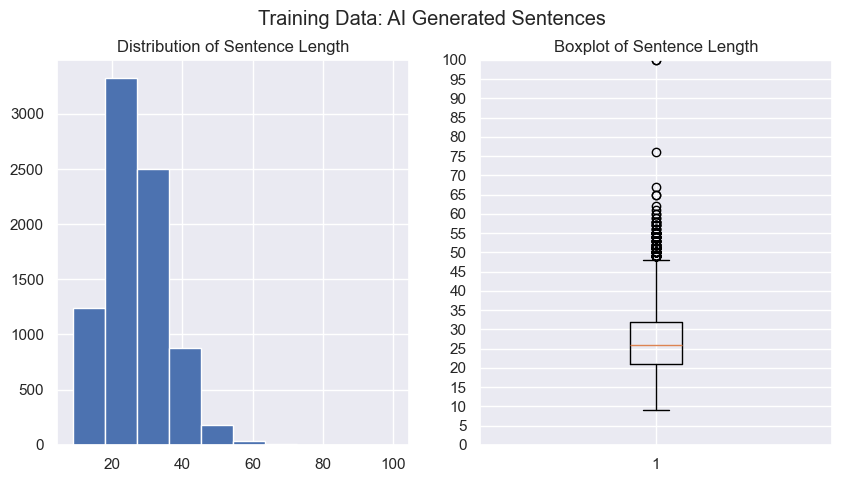

In [5]:
# Visualising AI data
fig, axes= sentence_length_plot(train_ai)
fig.suptitle('Training Data: AI Generated Sentences')
fig.show()

In [6]:
# Removing variables that are not needed to free up ram
del train_ai
del train_human

## Training, Testing Split
We split the data into the regular 80 - 20 split

In [7]:
#Train test split
X_train, X_val, y_train, y_val = train_test_split(features, labels, test_size=0.2, train_size=0.8, shuffle=True, random_state=42)
X_train.shape, X_val.shape, y_train.shape, y_val.shape  

((14133, 100, 768), (3534, 100, 768), (14133,), (3534,))

- Initially we use a feed forward neural network along with a batch size of 32 samples (this helps to train the model faster and introduces some noise (stochasticity), which often helps generalization).
- Since only have two classes, we use sigmoid in the last layer. 
- Binary cross entropy is used as we have a binary output.

# Testing different settings on NN model 

## Creating model functions 

In [8]:
#Setting seed for reproducibility
keras.utils.set_random_seed(42)

In [9]:
# Creating the model and compiling 
def model_factory(hiddensizes, actfn, optimizer, lr):
    model = keras.models.Sequential()
    model.add(keras.layers.Flatten(input_shape=[100,768]))
    for n in hiddensizes:
        model.add(keras.layers.Dense(n, activation = actfn))
    model.add(keras.layers.Dense(1, activation = 'sigmoid'))
    model.compile(loss = 'binary_crossentropy', optimizer=optimizer(learning_rate=lr), metrics = ['auc'])
    return model

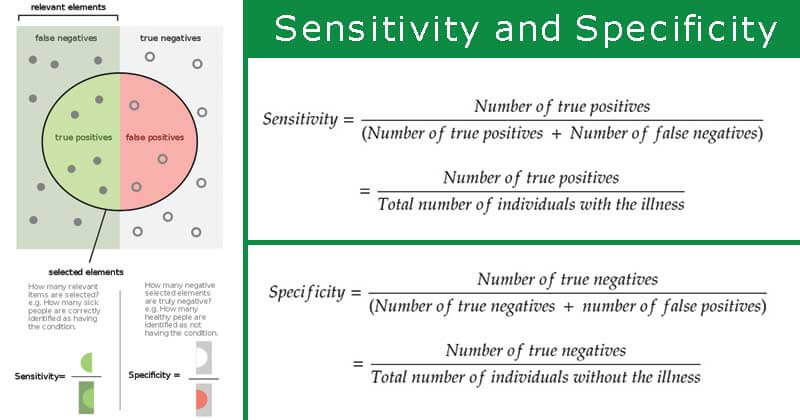

In [ ]:
# Code to load our created model
def load_model(model_name):
    model_path = '../Saved_Models/'
    model= tf.keras.models.load_model(model_path + model_name) #import model
    model.summary()
    return model

In [11]:
#Following function creates the model and fits it. Then it returns the max accuracy value, history and model
def do_all(hiddensizes, actfn, optimizer, lr, X_train, y_train, X_val, y_val, n_epochs, batch_size, callbacks=[]):
    model = model_factory(hiddensizes, actfn, optimizer, lr)
    history = model.fit(X_train, y_train, epochs= n_epochs,
                        validation_data = (X_val, y_val), 
                        batch_size = batch_size, callbacks = callbacks)
    print(model.summary())
    max_val_acc = np.max(history.history['val_auc'])
    return max_val_acc, history, model

In [ ]:
#Defining Schedulers
def exp_schedule(epoch):
  stretch = 5
  return 0.0000001 * (10**(epoch/stretch))

def exp_schedule_2(epoch):
  stretch = 5
  return 0.0001 * (10**(epoch/stretch)) # every 5 epochs, lr grows by x10 10^(5/5)

In [13]:
# Following function converts our paragraphs into sentences and then averages the probabilities for each sentence
def predict_paragraphs(model,data):
    import numpy as np
    from sklearn.metrics import roc_auc_score

    final_paragraph_probs = [] #average probability for each paragraph

    #For each paragraph in the validation json file
    for paragraph_sentences in data['features']:
        
        sentence_probabilities = []
        for sentence_vector in paragraph_sentences:
            np_sentence = np.array(sentence_vector)
            
            input_for_model = np.expand_dims(np_sentence, axis=0)
            
            # Get the predicted probability of the sentence being AI (class 1)
            prediction_prob = model.predict(input_for_model, verbose=0)[0][0]
            sentence_probabilities.append(prediction_prob)
            
        #a single score for the entire paragraph
        average_prob = np.mean(sentence_probabilities) if sentence_probabilities else 0
        final_paragraph_probs.append(average_prob)
    
    return  final_paragraph_probs


In [14]:
# Visualise our results using an ROC Plot
def ROC_AUC_Plot(data,paragraph_probs):
    from sklearn.metrics import roc_auc_score,roc_curve
    import matplotlib.pyplot as plt

    y_true = data['label']
    fpr, tpr, thresholds = roc_curve(y_true, paragraph_probs)
    roc_auc = roc_auc_score(y_true, paragraph_probs)
    plt.figure()
    plt.plot(fpr, tpr, color="blue", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")  # random guess line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver Operating Characteristic (ROC)")
    plt.legend(loc="lower right")
    plt.show()
    auc = roc_auc_score(y_true, paragraph_probs)

In [15]:
# Plot the results (shifting validation curves appropriately)
def plot_history(history):
    plt.figure(figsize=(8,5))
    n = len(history.history['auc'])
    plt.plot(np.arange(0,n),history.history['loss'], color='y')
    plt.plot(np.arange(0,n),history.history['auc'],'b')
    plt.plot(np.arange(0,n)+0.5,history.history['val_auc'],'r')  # offset both validation curves
    plt.plot(np.arange(0,n)+0.5,history.history['val_loss'],'g')
    plt.legend(['Train Loss','Train AUC','Val AUC','Val Loss'])
    plt.grid(True)
    plt.show()

## Running all the models with various settings and saving them

## Model 4
Adding scheduler (exp schedule 1), early stopping criteria and Nadam

/opt/homebrew/anaconda3/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 27s 59ms/step - auc: 0.6780 - loss: 0.6519 - val_auc: 0.7960 - val_loss: 0.6039 - learning_rate: 1.0000e-07
Epoch 2/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 24s 55ms/step - auc: 0.8187 - loss: 0.5629 - val_auc: 0.8113 - val_loss: 0.5519 - learning_rate: 1.5849e-07
Epoch 3/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 26s 58ms/step - auc: 0.8273 - loss: 0.5244 - val_auc: 0.8178 - val_loss: 0.5278 - learning_rate: 2.5119e-07
Epoch 4/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 25s 58ms/step - auc: 0.8359 - loss: 0.5045 - val_auc: 0.8285 - val_loss: 0.5116 - learning_rate: 3.9811e-07
Epoch 5/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 26s 58ms/step - auc: 0.8487 - loss: 0.4857 - val_auc: 0.8453 - val_loss: 0.4913 - learning_rate: 6.3096e-07
Epoch 6/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 25s 57ms/step - auc: 0.8666 - loss: 0.4611 - val_auc: 0.8676 - val_loss: 0.4632 - learning_rate: 1.0000e-06
Epoch 7/20
442/442 ━━━━━━━━━━━━━━━━━━━━ 25s 55ms/step - auc: 0.8871 - loss: 0.4302 - val_auc: 0.8887 - val_loss:

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 76800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │    23,040,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,211,506 (264.02 MB)

 Trainable params: 23,070,501 (88.01 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 46,141,005 (176.01 MB)

None


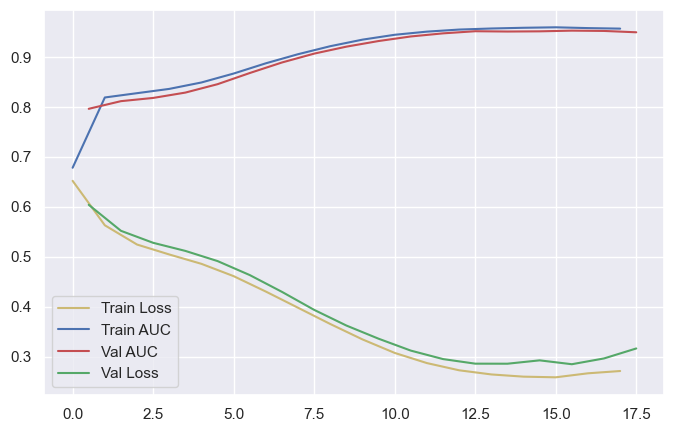

In [16]:
lr_scheduler = tf.keras.callbacks.LearningRateScheduler(exp_schedule)
early_stopping_cb = keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
callbacks = [lr_scheduler,early_stopping_cb]
hiddensizes = [300, 100] # 2 hidden layers
lr = 0.001
actfn = 'relu'
optimizer = keras.optimizers.Nadam
n_epochs = 20
batch_size = 32

# Applying functions using above settings
max_val_acc, history, model_4 = do_all(hiddensizes, 
                                       actfn, optimizer, lr, 
                                       X_train, y_train, X_val, y_val, 
                                       n_epochs, batch_size, 
                                       callbacks=callbacks)
model_4.save('../Saved_Models/FNN_model_4.keras')
plot_history(history)

#Deleting variables and clearing up memory
keras.backend.clear_session()
del model_4

## Running model on validation set and testing set and producing submission results

Loading the models and running the data

In [17]:
import json
DATA_PATH = '../train_files/'
val_df_1 = pd.read_json(DATA_PATH+'/validation.jsonl', lines=True) 
test_data = pd.read_json(DATA_PATH+'/test_features.jsonl', lines = True)

## Loading the model

In [18]:
#Loading the model and running the results for the validation set
model_name = 'FNN_model_4.keras'
model=load_model(model_name)
val_predict_paragraphs=predict_paragraphs(model,val_df_1)
y_true = val_df_1['label']
print('Validation Data AUC: ', roc_auc_score(y_true, val_predict_paragraphs))

#Outputting Submission CSV
test_prediction_paragraphs=predict_paragraphs(model,test_data)
submission_df = pd.DataFrame({
    'id': test_data['id'],
    'y_prob': test_prediction_paragraphs # 'y_prob' as the column name required
})

submission_df.to_csv('submission_'+model_name[:-6]+'.csv', index=False)
print(submission_df.head())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 76800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │    23,040,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,211,506 (264.02 MB)

 Trainable params: 23,070,501 (88.01 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 46,141,005 (176.01 MB)

Validation Data AUC:  0.9000000000000001
   id    y_prob
0  15  0.101985
1  16  0.170643
2  17  0.030448
3  18  0.188380
4  19  0.160374
